# Taller de Aprendizaje No Supervisado
## Parte 1: Dataset de Setas (variables categóricas)

### Mushroom Dataset

Podéis obtener el conjunto de datos en el siguiente enlace:

[Mushroom Dataset](https://www.kaggle.com/uciml/mushroom-classification)

Como podréis comprobar, hay **muchas variables, todas categóricas**, por lo que las exploraciones con *scatterplot* no nos serán útiles como en otros casos.

La variable a predecir es `class` (`e` = comestible / *edible*, `p` = venenosa / *poisonous*) y es **binaria**.

> En este taller usaremos las etiquetas **solo para validar** lo que descubre el clustering. La idea del aprendizaje no supervisado es encontrar estructura *sin* mirar la etiqueta.

### Algoritmos que cubriremos

**Reducción de dimensionalidad:** PCA (lineal) y t-SNE (no lineal).

**Clustering:** K-Means, Clustering Jerárquico (Aglomerativo), Gaussian Mixture Models (GMM) y DBSCAN.

**Evaluación:** método del codo, *silhouette*, Davies-Bouldin, Calinski-Harabasz y (como tenemos etiqueta) Adjusted Rand Index y NMI.

**Detección de anomalías:** Isolation Forest.

In [1]:
%matplotlib inline
# Hace que los gráficos aparezcan dentro del notebook, justo debajo de la celda que los crea.
import warnings
warnings.filterwarnings("ignore")  # oculta avisos (FutureWarning, etc.) para que la salida quede limpia en clase

# Tablas y cálculo numérico
import pandas as pd      # DataFrame: la "hoja de cálculo" con la que trabajamos
import numpy as np       # arrays y operaciones matemáticas rápidas
# Gráficos
import seaborn as sns            # gráficos estadísticos bonitos con poco código
import matplotlib.pyplot as plt  # base de todos los gráficos (títulos, ejes, plt.show())
# Preparación de datos y reducción de dimensiones
from sklearn.model_selection import train_test_split  # separa datos en entrenamiento y examen
from sklearn.decomposition import PCA                 # reducción de dimensiones lineal
# Algoritmos de clustering
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.manifold import TSNE                     # reducción de dimensiones no lineal (solo para visualizar)
from sklearn.mixture import GaussianMixture          # GMM: clusters como "nubes" probabilísticas
# Modelos supervisado y de anomalías
from sklearn.ensemble import RandomForestClassifier, IsolationForest
# Métricas para evaluar los clusters (3 internas + 2 que usan la etiqueta: ARI y NMI)
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
# Para dibujar el dendrograma
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style='whitegrid')  # estilo visual de todos los gráficos: fondo blanco con rejilla
RANDOM_STATE = 42 

### Leer conjunto de datos y primer vistazo

In [2]:
# Leer el csv (esta en 'data/mushrooms.csv') y sacar por pantalla las cinco primeras filas.
df = pd.read_csv("data/mushrooms.csv")  # cargamos el dataset en un DataFrame
df.head()                               # vistazo rápido a las 5 primeras filas


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### Exploración de datos

In [3]:
# Descripcion del conjunto de datos, estandar.
print("Filas y columnas:", df.shape)  # tamaño del dataset (filas, columnas)
print(df["class"].value_counts(normalize=True))     # proporción de cada clase (e / p)
df.describe()                                       # count, unique, top y freq de cada variable

Filas y columnas: (8124, 23)
class
e    0.517971
p    0.482029
Name: proportion, dtype: float64


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
count,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124,...,8124,8124,8124,8124,8124,8124,8124,8124,8124,8124
unique,2,6,4,10,2,9,2,2,2,12,...,4,9,9,1,4,3,5,9,6,7
top,e,x,y,n,f,n,f,c,b,b,...,s,w,w,p,w,o,p,w,v,d
freq,4208,3656,3244,2284,4748,3528,7914,6812,5612,1728,...,4936,4464,4384,8124,7924,7488,3968,2388,4040,3148


> **📝 Observación:** El dataset tiene 8124 filas y 23 columnas, todas categóricas.
> - `veil-type` tiene un único valor → no aporta información y la eliminaremos.
> - La variable `class` está bastante equilibrada: **51,8 %** comestibles (`e`) y **48,2 %** venenosas (`p`).
>   Esto es importante porque no hay desbalance que distorsione la validación posterior (ARI/NMI).

In [4]:
# Informacion sobre el tipo de datos de cada feature.
df.info()   # tipo de dato y número de valores no nulos de cada columna

<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null   str  
 14  stalk-color-above-ring    8124 non-null   str  
 15

> **📝 Observación:** Todas las variables son de tipo `object` (categóricas) y no aparecen nulos.
> Sin embargo, hay que comprobar si existen valores desconocidos codificados de otra forma (p. ej. `'?'`).

#### Calcular el número de nulos de cada feature

In [5]:
# Igual que otras veces, una linea: contar los nulos por variable.
df.isnull().sum()  # contamos los nulos de cada columna

class                       0
cap-shape                   0
cap-surface                 0
cap-color                   0
bruises                     0
odor                        0
gill-attachment             0
gill-spacing                0
gill-size                   0
gill-color                  0
stalk-shape                 0
stalk-root                  0
stalk-surface-above-ring    0
stalk-surface-below-ring    0
stalk-color-above-ring      0
stalk-color-below-ring      0
veil-type                   0
veil-color                  0
ring-number                 0
ring-type                   0
spore-print-color           0
population                  0
habitat                     0
dtype: int64

#### Buscar valores extraños. Para ello, ver los valores únicos en cada feature

In [6]:
# Obtener un nuevo dataframe: en una columna las features (feature)
# y en la otra el numero de valores unicos asociados (n_values).
n_values = pd.DataFrame({
    "feature": df.columns,                                    # nombre de la variable
    "n_values": df.nunique().values,                          # nº de valores distintos
    "valores": [sorted(df[c].unique()) for c in df.columns]   # (extra) cuáles son → aquí se ve el '?'
}).sort_values("n_values")                                    # de menor a mayor
n_values

,feature,n_values,valores
16,veil-type,1,[p]
0,class,2,"[e, p]"
4,bruises,2,"[f, t]"
6,gill-attachment,2,"[a, f]"
7,gill-spacing,2,"[c, w]"
8,gill-size,2,"[b, n]"
10,stalk-shape,2,"[e, t]"
18,ring-number,3,"[n, o, t]"
2,cap-surface,4,"[f, g, s, y]"
17,veil-color,4,"[n, o, w, y]"


In [7]:
# Buscamos el valor '?' (nulo encubierto) en cada columna
(df == "?").sum().loc[lambda s: s > 0]   # solo columnas que contienen '?'

stalk-root    2480
dtype: int64

Observad dos cosas:
- `veil-type` tiene **un único valor** → no aporta información.
- `stalk-root` contiene el valor `'?'`, que en realidad es un **valor desconocido (nulo encubierto)**.

#### Tratar aquellos valores que entendamos que sean nulos

**¿Qué hacemos con los 2480 `'?'` de `stalk-root`?**

| Opción | Consecuencia |
|---|---|
| A) Eliminar las filas | Perdemos 2480 filas (≈ 30 % de los datos) y la información de las otras 21 variables ❌ |
| B) Imputar con la moda | `'?'` se sustituye por el valor más frecuente; conserva todas las filas, pero distorsiona la distribución |
| C) Dejar `'?'` como categoría | "Desconocido" pasa a ser un valor más; no inventa información |

**Decisión:** imputamos con la **moda** (opción B), como indica el enunciado. Usamos la moda y no la media porque la variable es **categórica**.

In [8]:
df["stalk-root"].value_counts()

stalk-root
b    3776
?    2480
e    1120
c     556
r     192
Name: count, dtype: int64

In [9]:
# Imputaciones. Podeis quitar esos puntos (fila entera), imputar con la moda
# o dejar ese valor como una posibilidad mas. Aqui imputamos '?' con la moda.
df["stalk-root"] = df["stalk-root"].replace("?", np.nan)   # '?' → nulo real (NaN)
moda = df["stalk-root"].mode()[0]                          # valor más frecuente (sin contar NaN)
print("Moda de stalk-root:", moda)
df["stalk-root"] = df["stalk-root"].fillna(moda)           # imputamos con la moda (variable categórica)
df["stalk-root"].value_counts()                            # comprobamos el resultado

Moda de stalk-root: b


stalk-root
b    6256
e    1120
c     556
r     192
Name: count, dtype: int64

> **📝 Observación:** Imputamos los 2480 `'?'` de `stalk-root` con la moda (`b`).
> Efecto secundario: `b` pasa del 46,5 % al 77 % de las filas, lo que distorsiona la distribución.

> Alternativa válida: mantener `'?'` como una categoría propia ("desconocido"), ya que el 30 % de datos faltantes es mucho.

#### ¿Todas las features aportan información? Si alguna no aporta, eliminadla

`veil-type` tiene **un único valor** (`p`) en las 8124 filas.
Una variable que no cambia **no ayuda a distinguir** unas setas de otras: no aporta información
ni a los modelos supervisados ni al clustering (todas las setas son iguales en esa variable).
Por eso la eliminamos. Lo hacemos de forma automática: buscamos en `n_values` todas las columnas con un solo valor.

In [10]:
# Dejar por el camino las features con un solo valor (no aportan nada).
cols_constantes = n_values.loc[n_values["n_values"] == 1, "feature"].tolist() # columnas con un solo valor
print("Eliminamos:", cols_constantes)
df = df.drop(columns=cols_constantes) # las quitamos del DataFrame
df.shape                                # comprobamos el nuevo tamaño

Eliminamos: ['veil-type']


(8124, 22)

#### Separar entre variables predictoras y variable a predecir

Separamos la etiqueta `class` (**y**) del resto de variables (**X**).
El clustering **no verá nunca `y`**: la guardamos como una "hoja de respuestas"
y solo la usaremos al final para comprobar si los grupos encontrados coinciden con la realidad.

In [14]:
# La variable a predecir es 'class'.
y = df["class"]                    # etiqueta: solo la usaremos para VALIDAR el clustering
y_bin = (y == "p").astype(int)     # misma etiqueta en 0/1 (1 = venenosa), útil para gráficos y métricas
X = df.drop(columns=["class"])     # variables predictoras: todas menos 'class'
print(X.shape, y.shape)
print(y.value_counts())            # nº de setas de cada clase (casi mitad y mitad → equilibrado)

(8124, 21) (8124,)
class
e    4208
p    3916
Name: count, dtype: int64


#### Codificar correctamente las variables categóricas a numéricas

**Problema:** los modelos solo trabajan con **números**, pero nuestras variables son letras (`a`, `n`, `f`…).

**¿Por qué no numerarlas (`a=1`, `n=2`, `f=3`)?** Porque el modelo supondría un **orden falso**:
que `f` es "el triple" de `a`, o que `n` está "entre" `a` y `f`. Pero entre olores no existe ningún orden.

**Solución: One-Hot Encoding.** Cada valor se convierte en una columna nueva con 0 o 1. Ejemplo con `odor`:

| odor | → | odor_a (almendra) | odor_n (ninguno) | odor_f (fétido) |
|---|---|---|---|---|
| a | | **1** | 0 | 0 |
| n | | 0 | **1** | 0 |
| f | | 0 | 0 | **1** |

Cada seta tiene un **1** solo en la columna de su olor y **0** en las demás.
Consecuencia: el número de columnas **aumenta** (una por cada valor posible de cada variable).

In [15]:
# One Hot Encoder (una linea). Pista: pd.get_dummies
X = pd.get_dummies(X, dtype=int)   # cada categoría → una columna 0/1
print("Forma tras One-Hot:", X.shape)   # pasamos de 21 columnas de texto a 115 columnas numéricas
X.head()

Forma tras One-Hot: (8124, 115)


,cap-shape_b,cap-shape_c,cap-shape_f,cap-shape_k,cap-shape_s,cap-shape_x,cap-surface_f,cap-surface_g,cap-surface_s,cap-surface_y,...,population_s,population_v,population_y,habitat_d,habitat_g,habitat_l,habitat_m,habitat_p,habitat_u,habitat_w
0,0,0,0,0,0,1,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
1,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
2,1,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0
3,0,0,0,0,0,1,0,0,0,1,...,1,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0


> **📝 Observación:** Tras el One-Hot Encoding pasamos de **21 a 115 columnas** (una por cada valor posible de cada variable).
> Con tantas dimensiones no podemos visualizar los datos directamente → necesitaremos **PCA / t-SNE**.


#### Train / test split

In [ ]:
# Os lo dejamos a todos igual
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42)
print(X_train.shape, X_test.shape)

## PCA

Es un conjunto de datos del que aún no hemos visto gráficas, así que vamos a hacer algunas. Tenemos muchas variables, **PCA al rescate**: le pedimos dos dimensiones y las pintamos. Serán **las que retengan más información (varianza)**.

Varianza explicada: [0.1686744  0.12724955]


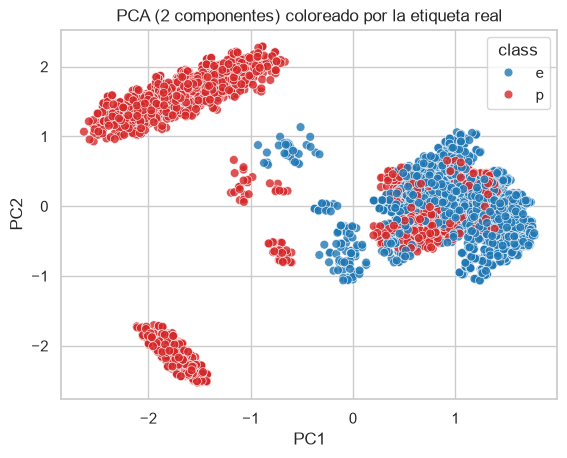

In [20]:
pca = PCA(n_components= 2)         # nos quedamos con 2 componentes para poder pintarlas
pca.fit(X_train)                    # PCA aprende las direcciones de máxima varianza

X_pca = pca.transform(X_train)      # proyectamos X_train a 2D
print("Varianza explicada:", pca.explained_variance_ratio_)

# Representar en un scatterplot y poner en color las etiquetas de entrenamiento
colores = {"e": "#1f77b4", "p": "#d62728"}   # azul = comestible, rojo = venenosa
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train,
                palette=colores, alpha=0.8, s=40,
                edgecolor="white", linewidth=0.5)   # borde blanco fino → cada punto se distingue
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("PCA (2 componentes) coloreado por la etiqueta real")
plt.legend(title="class", labels=None)
plt.show()

Parece que está bastante separadito, ¡a ojo mucho se puede ver! :)

> **📝 Observación:** Las 2 primeras componentes explican solo el **≈ 30 % de la varianza** (16,9 % + 12,7 %).
> Aun así, se ven **grupos bien definidos** y muchos son de un solo color (p. ej. dos grupos totalmente venenosos a la izquierda),
> sin que PCA haya usado la etiqueta. En el grupo grande de la derecha, en cambio, comestibles y venenosas se mezclan:
> 2 componentes no bastan para separarlas del todo.

Antes de seguir, entrenamos un clasificador supervisado como **línea base** (así sabemos cuánta información hay realmente en los datos).

**¿Por qué un modelo supervisado en un taller de clustering?**

Antes de agrupar sin etiquetas, queremos saber **cuánta información hay realmente** en los datos para distinguir comestibles de venenosas.
Random Forest **sí ve la etiqueta**: es como el profesor que resuelve el examen con la hoja de respuestas.
Su resultado marca el **techo** (lo mejor que se puede conseguir). Después compararemos cuánto se acerca el clustering **sin ver la etiqueta**.

- **Modelo:** `RandomForestClassifier` con 100 árboles (*ensemble*: cada árbol vota y gana la mayoría).
- **Entrenamiento** en `X_train` y **evaluación** en `X_test` (setas que el modelo no ha visto).
- **Métrica:** *accuracy* (proporción de aciertos). Como las clases están equilibradas (52 % / 48 %), la accuracy es fiable aquí.

In [21]:
# 1. Definir el clasificador y el numero de estimadores
rf = RandomForestClassifier(n_estimators=100, random_state=42)   # 100 árboles de decisión

# 2. Entrenar en train
rf.fit(X_train, y_train)          # aquí SÍ usamos la etiqueta (modelo supervisado)

# 3. Calcular la precision sobre test
acc = rf.score(X_test, y_test)    # accuracy sobre datos que el modelo no ha visto
print(f"Accuracy Random Forest (test): {acc:.4f}")

Accuracy Random Forest (test): 1.0000


Es un conjunto sencillo y Random Forest es muy bueno. Veamos cuántas features tenemos:

> **📝 Observación:** Random Forest obtiene una **accuracy de 1.0 (100 %)** en test.
> No es *data leakage*: `class` no está en `X` y el test no se usó para entrenar. Simplemente el dataset es muy separable
> (por ejemplo, `odor` por sí sola ya distingue casi todas las setas).
> Conclusión: **la información para separar comestibles y venenosas existe**. El techo es 100 %.

In [22]:
X_train.shape

(5443, 115)

¿Muchas features, no? Vamos a reducirlas con PCA y ver cuántas componentes necesita Random Forest para mantener su precisión.

**Objetivo:** averiguar con **cuántas componentes PCA** Random Forest mantiene la accuracy del 100 % obtenida con las 115 columnas.

**Cómo lo hacemos:** probamos distintos números de componentes (1, 2, 3… 30). Para cada uno:
1. Ajustamos PCA **solo con `X_train`** y proyectamos `X_test` con ese mismo PCA (`transform`), para que la información del test **no se filtre** en el entrenamiento.
2. Entrenamos un Random Forest con los datos reducidos.
3. Guardamos la accuracy en test.

Al final pintamos **nº de componentes vs accuracy** para ver a partir de qué punto ya no merece la pena añadir más.

**¿Por qué nos interesa?** Menos dimensiones = modelos más rápidos y menos ruido. Además, el clustering lo haremos sobre una versión reducida con PCA.


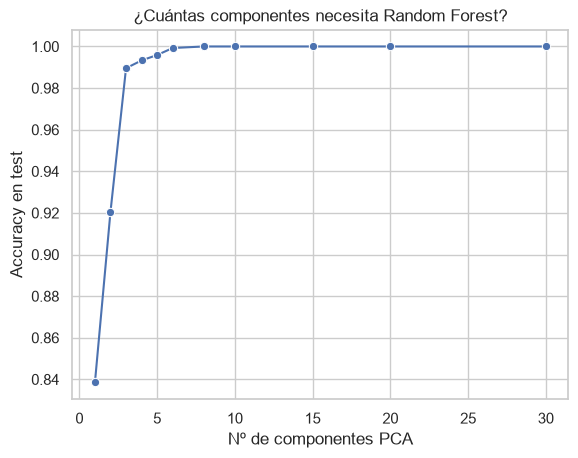

{1: 0.8385, 2: 0.9206, 3: 0.9896, 4: 0.9933, 5: 0.9959, 6: 0.9993, 8: 1.0, 10: 1.0, 15: 1.0, 20: 1.0, 30: 1.0}


In [23]:
n_features = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30]   # nº de componentes a probar
scores = []

for n in n_features:
    # 1. Definir y ajustar PCA sobre X_train
    pca_n = PCA(n_components=n, random_state=42)
    X_train_pca = pca_n.fit_transform(X_train)   # aprende y proyecta train
    X_test_pca = pca_n.transform(X_test)         # test: solo proyectar (sin aprender)

    # 2. Entrenar Random Forest sobre los datos reducidos
    rf_n = RandomForestClassifier(n_estimators=100, random_state=42)
    rf_n.fit(X_train_pca, y_train)

    # 3. Guardar el score en test
    scores.append(rf_n.score(X_test_pca, y_test))

sns.lineplot(x=list(n_features), y=scores, marker="o")
plt.xlabel("Nº de componentes PCA"); plt.ylabel("Accuracy en test")
plt.title("¿Cuántas componentes necesita Random Forest?")
plt.show()

print(dict(zip(n_features, [round(s, 4) for s in scores])))   # tabla número → accuracy

A partir de ~10 componentes ya tenemos la precisión que queríamos, reduciendo las variables a una fracción de las originales.

> **📝 Observación:** Con **1 sola componente** Random Forest ya acierta el 83,9 %, con **3** el 99 %,
> y a partir de **8 componentes** alcanza el **100 %**, igual que con las 115 columnas originales.
> Es decir, podemos reducir las dimensiones en un **~93 %** sin perder capacidad predictiva:
> la información relevante está concentrada en pocas direcciones.
> Por eso, para el clustering usaremos **PCA con 10 componentes** (`X_red`): margen suficiente, menos ruido y algoritmos más rápidos.

---
## t-SNE: reducción **no lineal** para visualizar

PCA es lineal. **t-SNE** intenta preservar la vecindad local y suele separar mejor los grupos visualmente. Es más caro, así que lo calculamos sobre una **muestra**.

In [ ]:
# 1. Tomar una muestra de X_train (t-SNE es lento)
# 2. Definir TSNE(n_components=2, ...) y ajustar
# 3. Pintar el embedding coloreado por la etiqueta

---
## Clustering

El conjunto es sencillito, así que probemos clustering para ver qué información obtenemos **sin usar las etiquetas**. Trabajaremos sobre una representación reducida con PCA (10 componentes), que limpia ruido y acelera los algoritmos.

In [ ]:
# Reducir X (one-hot completo) a 10 componentes con PCA -> X_red

### K-Means: ¿cuántos clusters? Codo + Silhouette

El **método del codo** mira la inercia (suma de distancias a los centroides). El **coeficiente de silhouette** mide cómo de bien separados están los clusters (cuanto más alto, mejor). Usamos ambos.

In [ ]:
from sklearn.cluster import KMeans

k_values = # definir un rango
inercias, silhouettes = [], []
for k in k_values:
    # Definir KMeans y ajustar sobre X_red
    # Guardar la inercia (km.inertia_) y el silhouette_score

# Pintar las dos curvas (codo y silhouette)

### K-Means final y comparación con la etiqueta

Sabemos que hay dos clases (comestible / venenosa), así que probamos `k=2`. Con `catplot` vemos la distribución de la etiqueta real dentro de cada cluster.

In [ ]:
# Aprender KMeans con el k obtenido y preparar el catplot.
kmeans = # Definir y entrenar KMeans

# ax = sns.catplot(col=, x=, data=, kind='count', col_wrap=4)
# Calcular ARI y NMI frente a y_bin

> **ARI / NMI** comparan los clusters con la etiqueta real (0 = aleatorio, 1 = idéntico). Sin haber visto la etiqueta, K-Means recupera buena parte de la estructura comestible/venenosa, pero **no es perfecto**: ese es el reto real del no supervisado.

### Comparativa de algoritmos de clustering

Vamos a poner a competir **K-Means, Aglomerativo, GMM y DBSCAN** con varias métricas. Las tres primeras métricas son *internas* (no usan etiqueta); ARI sí la usa, para validar.

In [ ]:
# Definir una funcion evaluar(nombre, labels, X) que devuelva silhouette,
# davies_bouldin, calinski_harabasz y ARI.
# Aplicarla a KMeans, AgglomerativeClustering, GaussianMixture y DBSCAN
# y montar una tabla (DataFrame) comparativa.

### Dendrograma (clustering jerárquico)

El clustering aglomerativo construye una jerarquía que podemos visualizar como **dendrograma**. La altura a la que se unen dos grupos indica cómo de distintos son. Lo calculamos sobre una muestra para que se lea bien.

In [ ]:
# 1. Tomar una muestra de X_red
# 2. linkage(..., method='ward')
# 3. dendrogram(...) para visualizar la jerarquia

### DBSCAN: la **métrica de distancia importa**

DBSCAN agrupa por densidad. Pero con datos **categóricos** codificados en one-hot, la distancia euclídea no captura bien la similitud. Comparemos euclídea (sobre PCA) con la distancia de **Jaccard** (pensada para datos binarios).

In [ ]:
# Comparar DBSCAN con metric='euclidean' (sobre X_red) y metric='jaccard'
# (sobre el one-hot binario). Observar cual recupera mejor la estructura (ARI).

> **Lección:** con datos categóricos, elegir la distancia adecuada (Jaccard/Hamming) puede cambiar por completo el resultado de un algoritmo basado en densidad. No hay un algoritmo que gane siempre: depende del tipo de datos.

### Visualización final: clusters vs etiqueta real

Repetimos el scatter PCA, pero coloreando por el cluster de K-Means y por la etiqueta real, lado a lado.

In [ ]:
# Entrenar PCA(2) sobre X para representar.
# Pintar dos scatter: uno coloreado por el cluster de KMeans y otro por la etiqueta real.

Es bastante parecido, ¿no? No es tan bueno como Random Forest (que usa etiquetas), pero K-Means ha identificado bastante bien la estructura **sin usarlas**. Si no tuviéramos etiquetas, esta aproximación nos ayudaría mucho a clasificar los tipos de hongos.

---
## Detección de anomalías (Isolation Forest)

Una tarea no supervisada distinta: encontrar las muestras **atípicas**. Isolation Forest aísla los puntos raros con pocos cortes aleatorios.

In [ ]:
# 1. Definir IsolationForest(contamination=...) y ajustar sobre X_red
# 2. predict -> -1 son anomalias
# 3. Pintarlas sobre la proyeccion PCA

---
## Para ir más allá (opcional)

- **UMAP** (`pip install umap-learn`): alternativa a t-SNE, más rápida y preserva mejor la estructura global.
- **HDBSCAN** (`pip install hdbscan`): DBSCAN jerárquico que no necesita fijar `eps`.
- **Reglas de asociación** (`mlxtend`, Apriori/FP-Growth): muy naturales aquí por ser datos categóricos; permiten descubrir reglas tipo «si olor = X entonces venenosa».

## Conclusiones

- PCA y t-SNE nos dejaron *ver* un dataset de >100 dimensiones.
- K-Means, GMM y Aglomerativo recuperan la estructura comestible/venenosa con ARI ~0.6 **sin usar la etiqueta**.
- DBSCAN nos enseñó que **la métrica de distancia importa** con datos categóricos.
- Isolation Forest localiza las setas más atípicas.
- El no supervisado no da una respuesta «perfecta», pero descubre estructura muy útil cuando no tenemos etiquetas.